# LOADING THE DATASETS

In [175]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns


In [176]:
try:
    excel_file = pd.ExcelFile("phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx")
    print(excel_file.sheet_names)
except FileNotFoundError as e:
    print(e)

['State_Txn and Users', 'State_TxnSplit', 'State_DeviceData', 'District_Txn and Users', 'District Demographics', 'Admin']


In [177]:
all_sheets = {name: pd.read_excel("phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",sheet_name = name) for name in excel_file.sheet_names[:-1]}

# TASK 1 VIEWING THE DATA

In [178]:
all_sheets["State_Txn and Users"].head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [179]:
all_sheets["State_TxnSplit"].tail(10)

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,202240249482.8529968262,3754.2922257873
2505,West Bengal,2021,1,Merchant payments,37143701,28918343691.0183982849,778.5531035536
2506,West Bengal,2021,1,Recharge & bill payments,26673733,11339665944.6912002563,425.1248201626
2507,West Bengal,2021,1,Financial Services,166727,175445811.8844430149,1052.2939409001
2508,West Bengal,2021,1,Others,400816,263502545.0738990009,657.4152356041
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,230812278789.2990112305,3569.5720255042
2510,West Bengal,2021,2,Merchant payments,41696787,34787867208.3192977905,834.3057034183
2511,West Bengal,2021,2,Recharge & bill payments,34799709,13331453857.6091995239,383.0909579620
2512,West Bengal,2021,2,Financial Services,190537,186466487.6307629943,978.6366303173
2513,West Bengal,2021,2,Others,549353,316744715.7049840093,576.5777481965


In [180]:
all_sheets["State_DeviceData"].iloc[int((all_sheets["State_DeviceData"].shape[0]/2)-1):int((all_sheets["State_DeviceData"].shape[0]/2)+9)]

,State,Year,Quarter,Brand,Registered Users,Percentage
2771,Ladakh,2021,2,Others,2610,0.0347777422
2772,Lakshadweep,2018,1,Samsung,102,0.2035928144
2773,Lakshadweep,2018,1,Xiaomi,100,0.1996007984
2774,Lakshadweep,2018,1,Vivo,67,0.1337325349
2775,Lakshadweep,2018,1,Oppo,56,0.1117764471
2776,Lakshadweep,2018,1,Huawei,25,0.0499001996
2777,Lakshadweep,2018,1,OnePlus,22,0.0439121756
2778,Lakshadweep,2018,1,Apple,20,0.0399201597
2779,Lakshadweep,2018,1,Realme,20,0.0399201597
2780,Lakshadweep,2018,1,Gionee,12,0.0239520958


In [181]:
all_sheets["District_Txn and Users"].head(10)


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1139848.8012259901,2158.8045477765,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,931663.0770939870,2107.8350160497,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,12560249.3436657991,2208.2013614040,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3072436.9081196301,2743.2472393925,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1317863.0834906499,1597.4097981705,911,0
5,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,23948235.5163431987,2549.0405020057,8143,0
6,Andaman & Nicobar Islands,2018,3,Nicobars,AN01,1471,6387829.1515589803,4342.5079208423,467,0
7,Andaman & Nicobar Islands,2018,3,North And Middle Andaman,AN02,1283,4901529.5184996696,3820.3659536241,1208,0
8,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,44268112.4642523974,3276.4497420067,10474,0
9,Andaman & Nicobar Islands,2018,4,Nicobars,AN01,1485,7180859.3549117800,4835.5955251931,536,0


In [182]:
all_sheets["District_Txn and Users"].tail(10)

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
10238,West Bengal,2021,2,Murshidabad,WB14,8602251,19996935608.2433013916,2324.6166158420,1248602,16530655
10239,West Bengal,2021,2,Nadia,WB15,5524174,11227582723.3773002625,2032.4455245938,955428,13665885
10240,West Bengal,2021,2,North Twenty Four Parganas,WB16,17258291,30414821772.9286003113,1762.3310310927,2660664,37899453
10241,West Bengal,2021,2,Paschim Bardhaman,WB17,4893774,8731262893.7299003601,1784.1573586622,789026,10545670
10242,West Bengal,2021,2,Paschim Medinipur,WB18,5051834,10303513378.7998008728,2039.5589757699,856640,16201033
10243,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7572502416.2386798859,1931.4016388888,787970,12128849
10244,West Bengal,2021,2,Purba Medinipur,WB20,6418522,15155067721.2733993530,2361.1460272744,946277,15491958
10245,West Bengal,2021,2,Purulia,WB21,1895981,2790996372.0372700691,1472.0592516683,435131,8843358
10246,West Bengal,2021,2,South Twenty Four Parganas,WB22,6661813,13398529483.6730995178,2011.2437085330,1286588,19344293
10247,West Bengal,2021,2,Uttar Dinajpur,WB23,2253385,5564220751.0492496490,2469.2721177470,392388,8184990


In [183]:
all_sheets["District Demographics"].loc[9::10]

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
9,Andhra Pradesh,Srikakulam,Srikakulam,2699471,5837.0000000000,462,AP09,Srikakulam
19,Arunachal Pradesh,Kurung Kumey,Koloriang,89717,6040.0000000000,15,AR07,Kurung Kumey
29,Arunachal Pradesh,Shi Yomi,Tato,13310,2875.0000000000,5,AR17,Shi Yomi
39,Assam,Bajali,Pathsala,253816,0.0000000000,0,AS01,Bajali
49,Assam,Dibrugarh,Dibrugarh,1327748,3381.0000000000,393,AS12,Dibrugarh
...,...,...,...,...,...,...,...,...
699,Andaman & Nicobar Islands,South Andaman,Port Blair,238142,2672.0000000000,89,AN03,South Andaman
709,Jammu & Kashmir,Ganderbal,Ganderbal,297003,1979.0000000000,1151,JK06,Ganderbal
719,Jammu & Kashmir,Reasi,Reasi,314714,1710.0000000000,184,JK16,Reasi
729,Delhi,New Delhi,Connaught Place,142004,22.0000000000,4057,DL03,New Delhi


# TASK 1.2 

In [184]:
for key,value in all_sheets.items():
    print(f"Data Set - {key}")
    print()
    print(value.describe())
    print()
    print()

Data Set - State_Txn and Users

                 Year        Quarter         Transactions  \
count  504.0000000000 504.0000000000       504.0000000000   
mean  2019.2857142857   2.3571428571  40740000.5833333358   
std      1.0311810123   1.1099713299  82287143.4855788797   
min   2018.0000000000   1.0000000000       778.0000000000   
25%   2018.0000000000   1.0000000000    592557.7500000000   
50%   2019.0000000000   2.0000000000   6217487.0000000000   
75%   2020.0000000000   3.0000000000  43636745.5000000000   
max   2021.0000000000   4.0000000000 573616486.0000000000   

                  Amount (INR)       ATV (INR)    Registered Users  \
count           503.0000000000  504.0000000000      504.0000000000   
mean    70833320601.5892181396 1993.4715430968  4777500.8869047621   
std    144090233156.0086059570  607.4648939786  6644495.7207246153   
min         1928611.1808777363    0.0000000000      501.0000000000   
25%      1167157028.9343409538 1598.9106667496   157420.2500000000  

In [185]:
for key,value in all_sheets.items():
    print(f"Data Set - {key}")
    print()
    print(value.dtypes)
    print()
    print()

Data Set - State_Txn and Users

State                object
Year                  int64
Quarter               int64
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object


Data Set - State_TxnSplit

State                object
Year                  int64
Quarter               int64
Transaction Type     object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
dtype: object


Data Set - State_DeviceData

State                object
Year                  int64
Quarter               int64
Brand                object
Registered Users      int64
Percentage          float64
dtype: object


Data Set - District_Txn and Users

State                object
Year                  int64
Quarter               int64
District             object
Code                 object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users 

# TASK 1.3

In [186]:
for var,data in all_sheets.items():
    if data.isna().any().any():
        print(f"{var} dataset has nulls")
        print()
        d = dict()
        null_series = data.isna().sum()
        for col,nulls in null_series.items():
            if nulls>=1:
                perct_nulls = (nulls/len(data[col]))*100
                print(f"{col} column has mising values")
                print(f"percentage of missing values {perct_nulls}")
                print()
                d[col] = perct_nulls
        key_l = sorted(d.items(), key = lambda item: item[1],reverse = True)
        
        print(f"highest percentage of nulls in {var} dataset are in {key_l[0][0]} column")
        print()
        print()
                

State_Txn and Users dataset has nulls

Amount (INR) column has mising values
percentage of missing values 0.1984126984126984

highest percentage of nulls in State_Txn and Users dataset are in Amount (INR) column


District_Txn and Users dataset has nulls

Code column has mising values
percentage of missing values 0.273224043715847

ATV (INR) column has mising values
percentage of missing values 0.039032006245121

highest percentage of nulls in District_Txn and Users dataset are in Code column




# Task 1.4 

In [187]:
tot_states = all_sheets["State_Txn and Users"]["State"].nunique()
print(f"Total number of states in dataset {tot_states}")

Total number of states in dataset 36


In [188]:
tot_districts = all_sheets["District Demographics"]["District"].nunique()
print(f"Total number of districts in dataset {tot_districts}")

Total number of districts in dataset 736


In [189]:
most_freq_state = all_sheets["District Demographics"]["State"].value_counts().idxmax()
print(f"State with highest number of districts is {most_freq_state}")

State with highest number of districts is Uttar Pradesh


# TASK 2.1

CHECKING DATASETS

In [190]:
all_sheets["State_Txn and Users"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             504 non-null    object 
 1   Year              504 non-null    int64  
 2   Quarter           504 non-null    int64  
 3   Transactions      504 non-null    int64  
 4   Amount (INR)      503 non-null    float64
 5   ATV (INR)         504 non-null    float64
 6   Registered Users  504 non-null    int64  
 7   App Opens         504 non-null    int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 31.6+ KB


In [191]:
all_sheets["State_Txn and Users"].isna().sum()

State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        1
ATV (INR)           0
Registered Users    0
App Opens           0
dtype: int64

In [192]:
all_sheets["State_Txn and Users"].shape

(504, 8)

In [193]:
all_sheets["State_Txn and Users"][all_sheets["State_Txn and Users"]["Amount (INR)"].isna()]

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
26,Andhra Pradesh,2021,1,289747970,NaN,0.0000000000,18363733,957709447


In [194]:
all_sheets["State_Txn and Users"][(all_sheets["State_Txn and Users"]["State"] == "Andhra Pradesh")]

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
14,Andhra Pradesh,2018,1,9039585,11996276391.8232192993,1327.0826472480,3336450,0
15,Andhra Pradesh,2018,2,12353918,22883914272.6330566406,1852.3608682390,4402540,0
16,Andhra Pradesh,2018,3,25626061,35718044599.2149047852,1393.8172003577,5427617,0
17,Andhra Pradesh,2018,4,30759548,51473779406.8409194946,1673.4244406596,6857409,0
18,Andhra Pradesh,2019,1,57264522,83760595917.0764007568,1462.6961509794,8283019,0
19,Andhra Pradesh,2019,2,56409015,113634518758.2297363281,2014.4744374322,9389003,81375251
20,Andhra Pradesh,2019,3,76288614,139447944254.7935485840,1827.8998259792,10458693,310953542
21,Andhra Pradesh,2019,4,107218103,200948315488.7905883789,1874.2013696026,11757883,411201518
22,Andhra Pradesh,2020,1,127677357,252737214289.0621337891,1979.4991079668,13022060,486513773
23,Andhra Pradesh,2020,2,144917855,302583689746.5629272461,2087.9669364866,14319675,494341698


In [195]:
all_sheets["State_Txn and Users"]["Amount (INR)"] = all_sheets["State_Txn and Users"].groupby(["State","Quarter"])["Amount (INR)"].transform(lambda amt: amt.fillna(amt.mean())) 

In [196]:
all_sheets["State_Txn and Users"][all_sheets["State_Txn and Users"]["State"] == "Andhra Pradesh"]

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
14,Andhra Pradesh,2018,1,9039585,11996276391.8232192993,1327.0826472480,3336450,0
15,Andhra Pradesh,2018,2,12353918,22883914272.6330566406,1852.3608682390,4402540,0
16,Andhra Pradesh,2018,3,25626061,35718044599.2149047852,1393.8172003577,5427617,0
17,Andhra Pradesh,2018,4,30759548,51473779406.8409194946,1673.4244406596,6857409,0
18,Andhra Pradesh,2019,1,57264522,83760595917.0764007568,1462.6961509794,8283019,0
19,Andhra Pradesh,2019,2,56409015,113634518758.2297363281,2014.4744374322,9389003,81375251
20,Andhra Pradesh,2019,3,76288614,139447944254.7935485840,1827.8998259792,10458693,310953542
21,Andhra Pradesh,2019,4,107218103,200948315488.7905883789,1874.2013696026,11757883,411201518
22,Andhra Pradesh,2020,1,127677357,252737214289.0621337891,1979.4991079668,13022060,486513773
23,Andhra Pradesh,2020,2,144917855,302583689746.5629272461,2087.9669364866,14319675,494341698


In [197]:
conditions = (all_sheets["State_Txn and Users"]["State"] == "Andra Pradesh") & (all_sheets["State_Txn and Users"]["Year"] == 2021) & (all_sheets["State_Txn and Users"]["Quarter"] == 1)
all_sheets["State_Txn and Users"].loc[conditions,"ATV (INR)"] = all_sheets["State_Txn and Users"]["Amount (INR)"]/all_sheets["State_Txn and Users"]["Transactions"]

In [198]:
all_sheets["State_Txn and Users"][all_sheets["State_Txn and Users"]["State"] == "Andhra Pradesh"]

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
14,Andhra Pradesh,2018,1,9039585,11996276391.8232192993,1327.0826472480,3336450,0
15,Andhra Pradesh,2018,2,12353918,22883914272.6330566406,1852.3608682390,4402540,0
16,Andhra Pradesh,2018,3,25626061,35718044599.2149047852,1393.8172003577,5427617,0
17,Andhra Pradesh,2018,4,30759548,51473779406.8409194946,1673.4244406596,6857409,0
18,Andhra Pradesh,2019,1,57264522,83760595917.0764007568,1462.6961509794,8283019,0
19,Andhra Pradesh,2019,2,56409015,113634518758.2297363281,2014.4744374322,9389003,81375251
20,Andhra Pradesh,2019,3,76288614,139447944254.7935485840,1827.8998259792,10458693,310953542
21,Andhra Pradesh,2019,4,107218103,200948315488.7905883789,1874.2013696026,11757883,411201518
22,Andhra Pradesh,2020,1,127677357,252737214289.0621337891,1979.4991079668,13022060,486513773
23,Andhra Pradesh,2020,2,144917855,302583689746.5629272461,2087.9669364866,14319675,494341698


In [199]:
all_sheets["State_Txn and Users"].isna().sum()

State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        0
ATV (INR)           0
Registered Users    0
App Opens           0
dtype: int64

# TASK 2.1

In [200]:
task_2a = all_sheets["State_Txn and Users"].groupby("State").agg({"Transactions":"sum","Amount (INR)":"sum"}).reset_index().copy() 

In [201]:
task_2a.head()

,State,Transactions,Amount (INR)
0,Andaman & Nicobar Islands,1223565,3641817860.7512121201
1,Andhra Pradesh,1781091169,3304012164384.1645507812
2,Arunachal Pradesh,8043799,22251830956.9066734314
3,Assam,123577981,281408712657.4358520508
4,Bihar,713643889,1639578926751.5102539062


In [202]:
task2a_cpy =  all_sheets["State_Txn and Users"].copy()

In [203]:
top_states = " ".join(list(task2a_cpy.groupby("State")["Transactions"].sum().sort_values(ascending = False).index[:5]))
print(f"Top 5 states by highest transaction volume are - {top_states}")

Top 5 states by highest transaction volume are - Karnataka Maharashtra Telangana Andhra Pradesh Rajasthan


In [204]:
low_states = " ".join(list(task2a_cpy.groupby("State")["Transactions"].sum().sort_values().index[:5]))
print(f"Top 5 states by lowest transaction volume are - {low_states}")

Top 5 states by lowest transaction volume are - Lakshadweep Andaman & Nicobar Islands Ladakh Mizoram Meghalaya


# TASK 2.2

In [205]:
all_sheets["State_TxnSplit"].head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1845307.4673655001,439.3589208013
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,12138655.2997498997,6487.7901121058
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,452507.1686466130,1518.4804317000
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,10601.4199334649,321.2551494989
4,Andaman & Nicobar Islands,2018,1,Others,256,184689.8662902220,721.4447901962


In [206]:
freq_ttype_state_quart = all_sheets["State_TxnSplit"].groupby(["State","Quarter","Transaction Type"])["Transactions"].sum().reset_index().copy()
freq_ttype_state_quart = freq_ttype_state_quart.sort_values(ascending = False,by = "Transactions")
freq_ttype_state_quart = freq_ttype_state_quart.drop_duplicates(subset = ["State","Quarter"])
freq_ttype_state_quart = freq_ttype_state_quart.sort_values(by = ["State","Quarter"])
print(freq_ttype_state_quart[["State","Quarter","Transaction Type"]])

                         State  Quarter          Transaction Type
3    Andaman & Nicobar Islands        1     Peer-to-peer payments
9    Andaman & Nicobar Islands        2  Recharge & bill payments
14   Andaman & Nicobar Islands        3  Recharge & bill payments
18   Andaman & Nicobar Islands        4     Peer-to-peer payments
23              Andhra Pradesh        1     Peer-to-peer payments
..                         ...      ...                       ...
698                Uttarakhand        4     Peer-to-peer payments
703                West Bengal        1     Peer-to-peer payments
708                West Bengal        2     Peer-to-peer payments
713                West Bengal        3     Peer-to-peer payments
718                West Bengal        4     Peer-to-peer payments

[144 rows x 3 columns]


In [207]:
most_freq_t_type_india = freq_ttype_state_quart["Transaction Type"].mode()[0]

In [208]:
print(f"The most frequent transaction type in most of the states is - {most_freq_t_type_india}")

The most frequent transaction type in most of the states is - Peer-to-peer payments


# TASK 2.3

In [209]:
all_sheets["State_DeviceData"].head()

,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.2470326409
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.2143916914
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.1456973294
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.0743323442
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.0492581602


In [210]:
top_brand_per_state = all_sheets["State_DeviceData"].groupby(["State","Brand"])["Registered Users"].mean().reset_index().sort_values(by = "Registered Users",ascending = False).copy() 


In [211]:
top_brand_per_state = top_brand_per_state.drop_duplicates(subset = ["State"])
top_brand_per_state = top_brand_per_state[["State","Brand"]]
top_brand_per_state = top_brand_per_state.sort_values(by = "State")
print(top_brand_per_state)

                                    State    Brand
11              Andaman & Nicobar Islands   Xiaomi
22                         Andhra Pradesh   Xiaomi
34                      Arunachal Pradesh   Xiaomi
46                                  Assam   Xiaomi
60                                  Bihar   Xiaomi
73                             Chandigarh   Xiaomi
85                           Chhattisgarh   Xiaomi
98   Dadra & Nagar Haveli and Daman & Diu   Xiaomi
109                                 Delhi   Xiaomi
120                                   Goa   Xiaomi
131                               Gujarat   Xiaomi
143                               Haryana   Xiaomi
156                      Himachal Pradesh   Xiaomi
168                       Jammu & Kashmir   Xiaomi
182                             Jharkhand   Xiaomi
193                             Karnataka   Xiaomi
204                                Kerala   Xiaomi
216                                Ladakh   Xiaomi
229                           L

In [212]:
top_d_brand_all_india = top_brand_per_state["Brand"].mode()[0]

In [213]:
print(f"The most common device brand used for transactions in most of the states is  - {top_d_brand_all_india}")

The most common device brand used for transactions in most of the states is  - Xiaomi


# TASK 2.4 

In [214]:
all_sheets["District Demographics"][["State","District"]].duplicated().any()

np.False_

In [215]:
all_sheets["District Demographics"].head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0000000000,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0000000000,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0000000000,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0000000000,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0000000000,188,AP13,YSR


In [216]:
max_pop_districts = all_sheets["District Demographics"].sort_values(by = "Population",ascending = False).copy()
max_pop_districts = max_pop_districts.drop_duplicates(subset = ["State"])
max_pop_districts = max_pop_districts.sort_values(by = "State").reset_index(drop = True)
max_pop_districts = max_pop_districts[["State","District","Population"]]
max_pop_districts

,State,District,Population
0,Andaman & Nicobar Islands,South Andaman,238142
1,Andhra Pradesh,East Godavari,5151549
2,Arunachal Pradesh,Papum Pare,176385
3,Assam,Nagaon,2826006
4,Bihar,Patna,5772804
5,Chandigarh,Chandigarh,1055450
6,Chhattisgarh,Raipur,2160876
7,Dadra & Nagar Haveli and Daman & Diu,Dadra and Nagar Haveli,343709
8,Delhi,North West Delhi,3656539
9,Goa,North Goa,817761


In [217]:
district_highst_pop = max_pop_districts.loc[max_pop_districts["Population"].idxmax(),"District"]
print(f"District with highest population in all of India is: {district_highst_pop}")

District with highest population in all of India is: North 24 Parganas


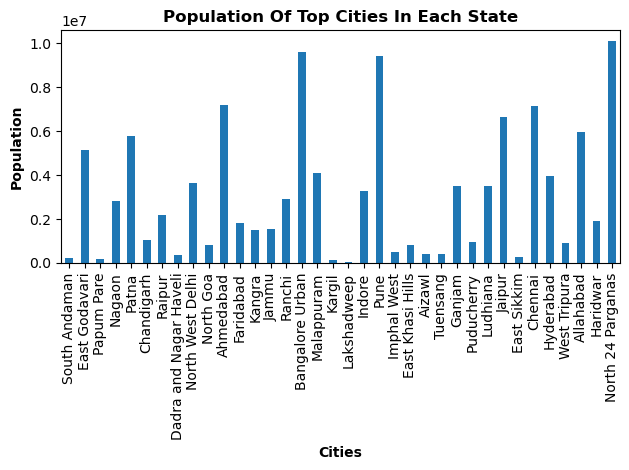

In [218]:

max_pop_districts.plot.bar(x = "District", y = "Population",legend = False)
plt.title("Population Of Top Cities In Each State",fontweight = "bold")
plt.xlabel("Cities",fontweight = "bold")
plt.ylabel("Population",fontweight = "bold")
plt.tight_layout()
plt.show()

# TASK 2.5

In [219]:
all_sheets["State_Txn and Users"].head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [220]:
state_atv = all_sheets["State_Txn and Users"].groupby("State").agg({"Amount (INR)":"sum","Transactions":"sum"}).copy()
state_atv["avg_trans_val"] = state_atv["Amount (INR)"]/state_atv["Transactions"]
state_atv = state_atv.sort_values(by = "avg_trans_val", ascending = False)
state_atv[["avg_trans_val"]]

,avg_trans_val
State,
Ladakh,3514.1464938979
Andaman & Nicobar Islands,2976.3991784263
Mizoram,2920.8486845356
Manipur,2905.7579305790
Nagaland,2794.1409965080
Arunachal Pradesh,2766.3335392775
Lakshadweep,2683.4057348656
Jammu & Kashmir,2430.3517802367
Bihar,2297.4749059352


In [221]:
states_by_atv = state_atv["avg_trans_val"].index
top_5 = states_by_atv[:5]
top_5 = " , ".join(list(top_5))
print(f"Top 5 states with highest avg transaction value are - {top_5}")

Top 5 states with highest avg transaction value are - Ladakh , Andaman & Nicobar Islands , Mizoram , Manipur , Nagaland


In [222]:
low_5 = states_by_atv[-5:]
low_5 = " , ".join(list(low_5))
print(f"Top 5 states with lowest avg transaction value are - {low_5}")

Top 5 states with lowest avg transaction value are - Delhi , West Bengal , Maharashtra , Dadra & Nagar Haveli and Daman & Diu , Karnataka


# TASK 2.6

In [223]:
all_sheets["State_Txn and Users"].tail()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
499,West Bengal,2020,2,57676797,100099431877.3553466797,1735.5234181495,13222022,198589332
500,West Bengal,2020,3,79954504,156813355855.1406860352,1961.2823294500,14448366,246554831
501,West Bengal,2020,4,100340645,199165491365.6471862793,1984.8934732844,15662093,291721919
502,West Bengal,2021,1,118254052,242937207475.5209350586,2054.3668767944,16808799,316832674
503,West Bengal,2021,2,141897437,279434811058.5632324219,1969.2731381650,17979979,275341466


In [224]:
tot_apps_open_by_state = all_sheets["State_Txn and Users"].copy()

tot_apps_open_by_state = tot_apps_open_by_state.groupby("State")["App Opens"].sum()
tot_apps_open_by_state = tot_apps_open_by_state.sort_values(ascending = False)
tot_apps_open_by_state

State
Maharashtra                             6145385557
Karnataka                               6010582453
Andhra Pradesh                          5352179585
Telangana                               4737814072
Rajasthan                               3914112235
Uttar Pradesh                           3744913382
Madhya Pradesh                          2937727396
Bihar                                   2043130469
West Bengal                             2006508265
Odisha                                  1829219041
Tamil Nadu                              1813864244
Gujarat                                 1595240265
Delhi                                   1580569662
Haryana                                 1513882526
Jharkhand                                842564361
Chhattisgarh                             776817670
Kerala                                   524877741
Punjab                                   501690418
Assam                                    381699610
Uttarakhand              

In [225]:
top_states_apps_open = list(tot_apps_open_by_state.index)[:5]
top_states_apps_open = " , ".join(top_states_apps_open)

In [226]:
print(f"States with highest number of apps open are - {top_states_apps_open}")

States with highest number of apps open are - Maharashtra , Karnataka , Andhra Pradesh , Telangana , Rajasthan


Enter a state  Goa


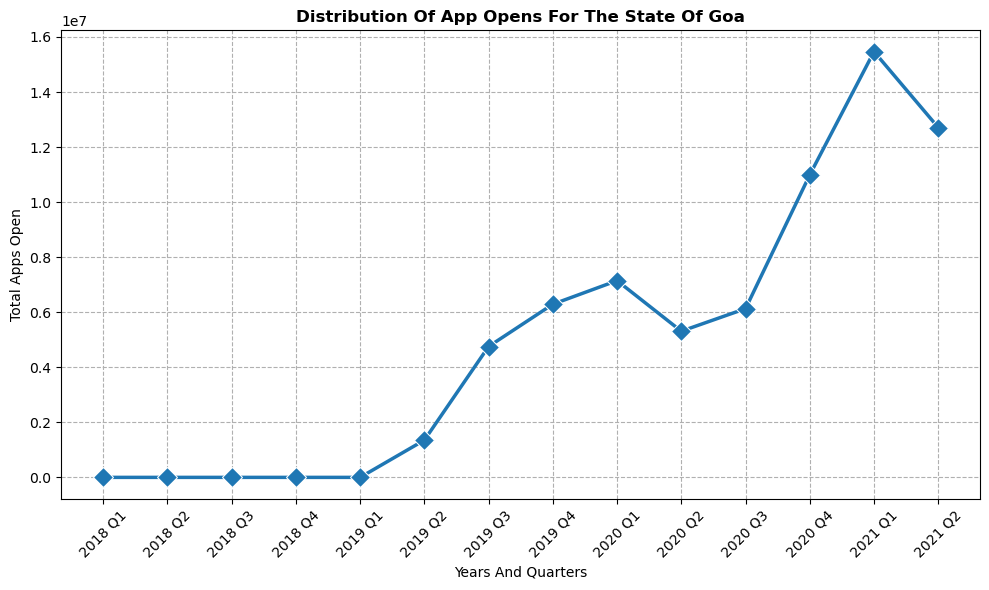

In [227]:
state = input("Enter a state ")
app_open_by_selected_state = all_sheets["State_Txn and Users"][all_sheets["State_Txn and Users"]["State"] == state].copy()
app_open_by_selected_state["Year_Quarter"] = app_open_by_selected_state["Year"].astype("str") + " Q" + app_open_by_selected_state["Quarter"].astype("str")
app_open_by_selected_state = app_open_by_selected_state.sort_values(by = ["Year","Quarter"])

plt.figure(figsize = (10,6))
sns.lineplot(data = app_open_by_selected_state,x = "Year_Quarter",y = "App Opens", marker = "D", linewidth = 2.5, markersize = 10)
plt.title(f"Distribution Of App Opens For The State Of {state}",fontweight = "bold")
plt.xlabel("Years And Quarters")
plt.ylabel("Total Apps Open")
plt.grid(True,linestyle = "--")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

# TASK 2.7 

In [228]:
y_max = all_sheets["State_TxnSplit"]["Year"].max()
q_max = all_sheets["State_TxnSplit"][all_sheets["State_TxnSplit"]["Year"] == y_max]["Quarter"].max()
t_type_dist_by_state = all_sheets["State_TxnSplit"].copy()
t_type_dist_by_state = t_type_dist_by_state[(t_type_dist_by_state["Year"] == y_max) & (t_type_dist_by_state["Quarter"] == q_max)]


In [229]:
t_type_dist_by_state.head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
65,Andaman & Nicobar Islands,2021,2,Peer-to-peer payments,132772,748382044.7707300186,5636.5954024247
66,Andaman & Nicobar Islands,2021,2,Recharge & bill payments,120911,43691961.2627511993,361.3563800047
67,Andaman & Nicobar Islands,2021,2,Merchant payments,85143,103707408.5090840012,1218.0379891369
68,Andaman & Nicobar Islands,2021,2,Financial Services,960,2038521.5136710301,2123.4599100740
69,Andaman & Nicobar Islands,2021,2,Others,1628,1327080.0560584499,815.1597395936


In [230]:
most_pop_t_type_recent = t_type_dist_by_state.groupby("Transaction Type")["Transactions"].sum().sort_values(ascending = False)
most_pop_t_type_recent = list(most_pop_t_type_recent.index)[0]
print(f" The most common transaction types in recent quarter is - {most_pop_t_type_recent}")

 The most common transaction types in recent quarter is - Peer-to-peer payments


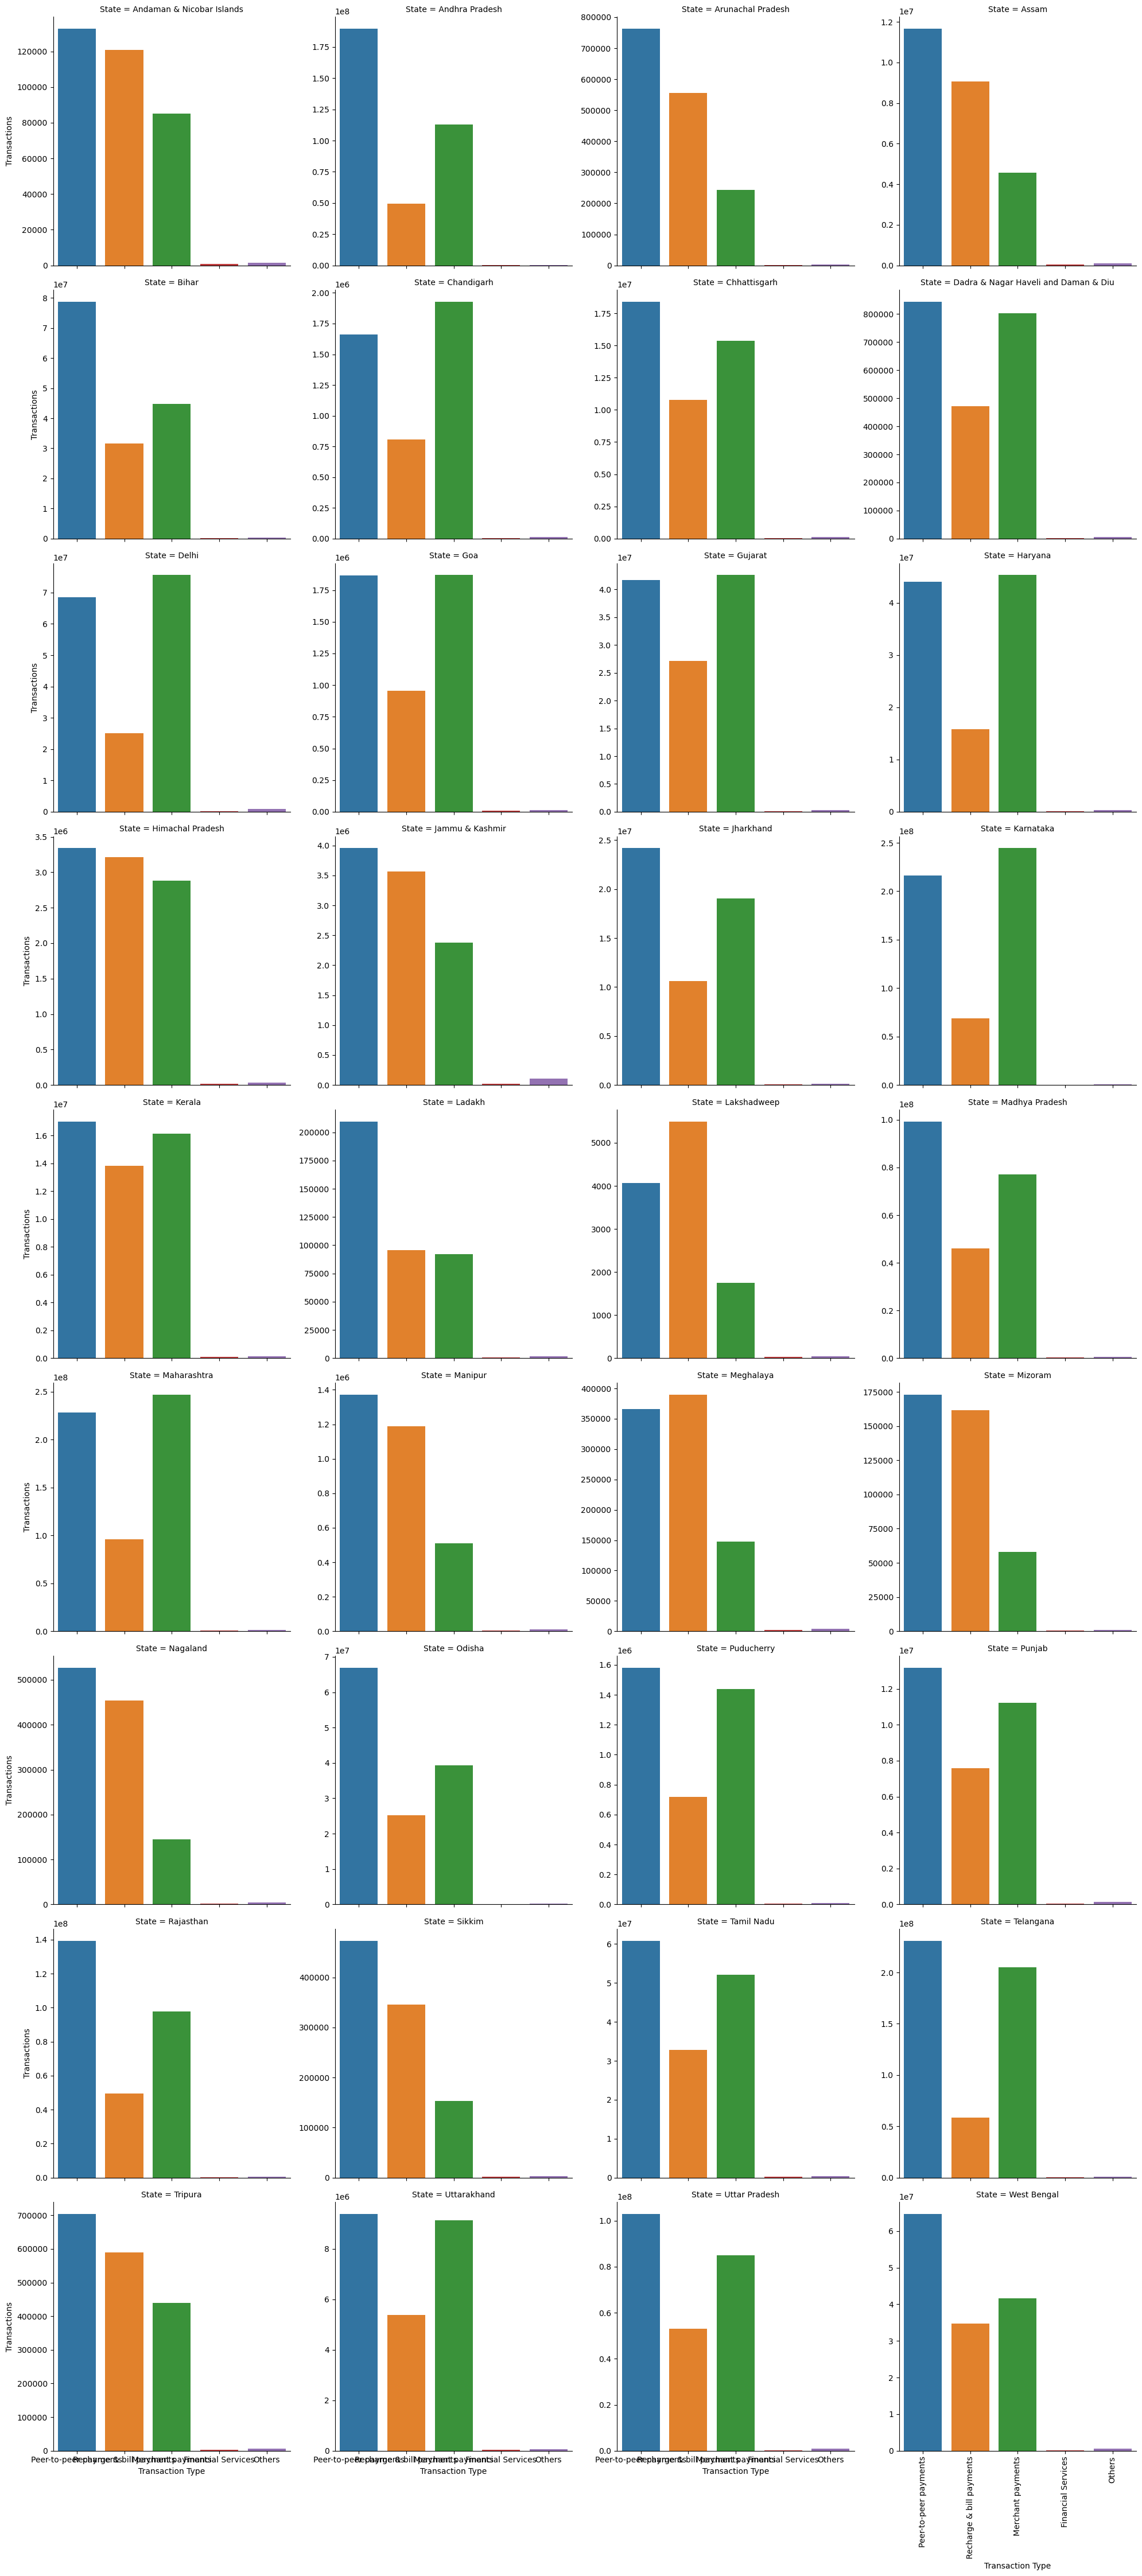

In [231]:
graph = sns.catplot(data = t_type_dist_by_state,kind = "bar", x = "Transaction Type", y = "Transactions",col = "State", col_wrap = 4,sharey = False,hue = "Transaction Type")
plt.xticks(rotation = "vertical")
plt.tight_layout()
plt.show()

# TASK 2.8

In [232]:
all_sheets["District_Txn and Users"][["District","Code"]].duplicated().any()

np.True_

In [233]:
unique_district_codes = all_sheets["District_Txn and Users"].copy()
unique_district_codes = unique_district_codes.drop_duplicates(subset = ["District","Code"])
unique_district_codes[["District","Code"]].duplicated().any()


np.False_

In [234]:
unique_district_codes = unique_district_codes[["District","Code"]]
unique_district_codes.head()
unique_district_codes.to_csv("unique_district_codes.csv",index = False)

# TASK 3

In [235]:
all_sheets["District_Txn and Users"].head()

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1139848.8012259901,2158.8045477765,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,931663.0770939870,2107.8350160497,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,12560249.3436657991,2208.2013614040,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3072436.9081196301,2743.2472393925,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1317863.0834906499,1597.4097981705,911,0


In [236]:
cal_state_data = all_sheets["District_Txn and Users"].groupby(["State","Year","Quarter"]).agg({"Transactions":"sum","Amount (INR)":"sum","Registered Users":"sum"}).reset_index().copy()
cal_state_data.columns

Index(['State', 'Year', 'Quarter', 'Transactions', 'Amount (INR)',
       'Registered Users'],
      dtype='object')

In [237]:
cal_state_data.head()

,State,Year,Quarter,Transactions,Amount (INR),Registered Users
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219857760,6740
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534799,9405
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110502,12149
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744551718,15222
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,18596


In [238]:
flag_dataframe = pd.merge(cal_state_data,all_sheets["State_Txn and Users"],on = ["State","Year","Quarter"], suffixes = ["_calc","_original"])
flag_dataframe.isna().any().any()

np.False_

In [239]:
flag_dataframe.head()

,State,Year,Quarter,Transactions_calc,Amount (INR)_calc,Registered Users_calc,Transactions_original,Amount (INR)_original,ATV (INR),Registered Users_original,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219857760,6740,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534799,9405,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110502,12149,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744551718,15222,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,18596,30486,102299740.6734898388,3355.6301473952,18596,0


In [240]:
pd.set_option('display.float_format', lambda x: f'{x:.10f}')

In [241]:
flag_dataframe["No Discrepancies"] = (flag_dataframe["Transactions_calc"] == flag_dataframe["Transactions_original"]) & (flag_dataframe["Registered Users_calc"] == flag_dataframe["Registered Users_original"]) & (flag_dataframe["Amount (INR)_calc"] == flag_dataframe["Amount (INR)_original"]) 

In [242]:
flag_dataframe[flag_dataframe["No Discrepancies"] == False]

,State,Year,Quarter,Transactions_calc,Amount (INR)_calc,Registered Users_calc,Transactions_original,Amount (INR)_original,ATV (INR),Registered Users_original,App Opens,No Discrepancies
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219857760,6740,6658,14631761.2219856996,2197.6210907158,6740,0,False
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534799,9405,11340,28338535.5079534650,2498.9890218654,9405,0,False
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110502,12149,16265,55557471.1343110576,3415.7682836957,12149,0,False
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744551718,15222,23758,90548336.0744550675,3811.2777201134,15222,0,False
5,Andaman & Nicobar Islands,2019,2,33689,120254709.6756625772,21731,33689,120254709.6756627411,3569.5541475159,21731,52640,False
...,...,...,...,...,...,...,...,...,...,...,...,...
499,West Bengal,2020,2,57676797,100099431877.3544769287,13222022,57676797,100099431877.3553466797,1735.5234181495,13222022,198589332,False
500,West Bengal,2020,3,79954504,156813355855.1405334473,14448366,79954504,156813355855.1406860352,1961.2823294500,14448366,246554831,False
501,West Bengal,2020,4,100340645,199165491365.6482543945,15662093,100340645,199165491365.6471862793,1984.8934732844,15662093,291721919,False
502,West Bengal,2021,1,118254052,242937207475.5218505859,16808799,118254052,242937207475.5209350586,2054.3668767944,16808799,316832674,False


# TASK 4 PART 1

In [243]:
df1 = all_sheets["State_Txn and Users"].copy()
df1.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [244]:
all_sheets["District Demographics"].head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0000000000,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0000000000,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0000000000,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0000000000,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0000000000,188,AP13,YSR


In [245]:
df2 = all_sheets["District Demographics"].copy()
df2 = df2.groupby("State")["Population"].sum()
df2 = df2.reset_index()
state_user_pop_ratio = pd.merge(df1,df2,on = "State")
state_user_pop_ratio["state user population ratio"] = state_user_pop_ratio["Registered Users"]/state_user_pop_ratio["Population"]
state_user_pop_ratio.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Population,state user population ratio
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0,380581,0.0177097648
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0,380581,0.0247122163
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0,380581,0.0319222452
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0,380581,0.0399967418
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0,380581,0.0488621345


In [246]:
ratio_users_series = state_user_pop_ratio.groupby("State")["state user population ratio"].mean()
ratio_users_series

State
Andaman & Nicobar Islands              0.0766489732
Andhra Pradesh                         0.2285654598
Arunachal Pradesh                      0.0828215399
Assam                                  0.0556746362
Bihar                                  0.0793179372
Chandigarh                             0.2572677869
Chhattisgarh                           0.1034053348
Dadra & Nagar Haveli and Daman & Diu   0.3287070435
Delhi                                  0.4057957605
Goa                                    0.2330111511
Gujarat                                0.1369194636
Haryana                                0.2363812956
Himachal Pradesh                       0.1393251705
Jammu & Kashmir                        0.0568512923
Jharkhand                              0.0970011501
Karnataka                              0.2379531182
Kerala                                 0.1096791362
Ladakh                                 0.1495840052
Lakshadweep                            0.0379150962
Madhya

In [247]:
user_pop_india = float(ratio_users_series.mean())
print(f"The average user to population mean in all india is - {user_pop_india}")

The average user to population mean in all india is - 0.14177131158875106


In [248]:
ratio_users_series = ratio_users_series.reset_index()

In [249]:
ratio_users_series.columns

Index(['State', 'state user population ratio'], dtype='object')

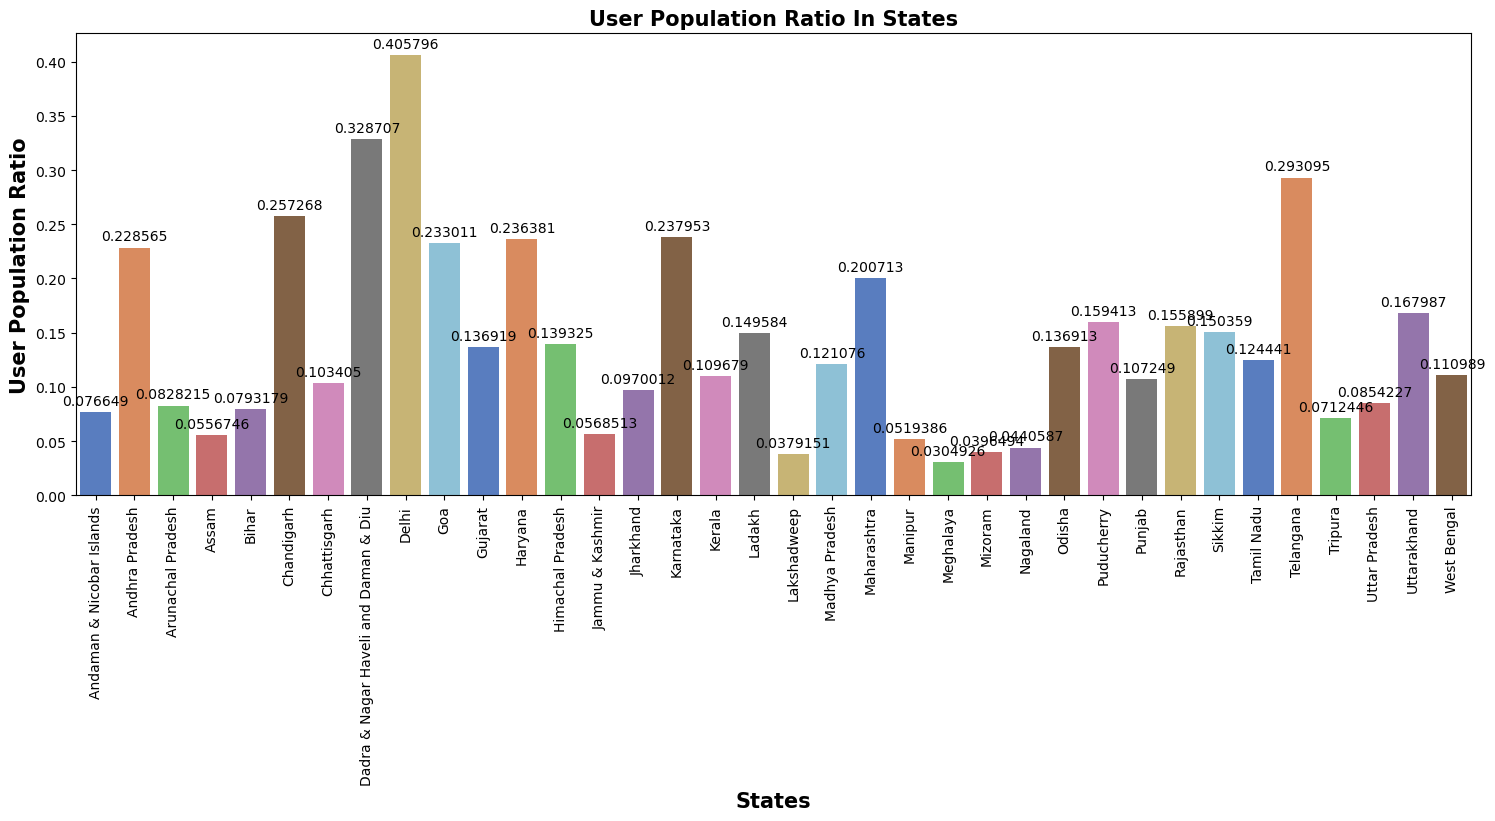

In [250]:
plt.figure(figsize = (18,6))


user_ratios = sns.barplot(x = ratio_users_series["State"],y = ratio_users_series["state user population ratio"],hue =  ratio_users_series["State"], legend = False,palette = "muted")
for container in user_ratios.containers:
    user_ratios.bar_label(container,padding = 3,fmt = "%g")
plt.title("User Population Ratio In States",fontweight = "bold",fontsize = 15)
plt.xlabel("States",fontweight = "bold",fontsize = 15)
plt.ylabel("User Population Ratio",fontweight = "bold",fontsize = 15)
plt.xticks(rotation = "vertical")



plt.show()

# TASK 4 PART 2

In [251]:
transaction_vol_by_state = all_sheets["District_Txn and Users"].copy()
pop_density = all_sheets["District Demographics"].copy()

In [252]:
transaction_vol_by_state.head()

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1139848.8012259901,2158.8045477765,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,931663.0770939870,2107.8350160497,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,12560249.3436657991,2208.2013614040,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3072436.9081196301,2743.2472393925,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1317863.0834906499,1597.4097981705,911,0


In [253]:
transaction_vol_by_state.rename(columns = {"Transactions": "transaction_volume"},inplace = True)


In [254]:
transaction_vol_by_state.head()

,State,Year,Quarter,District,Code,transaction_volume,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1139848.8012259901,2158.8045477765,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,931663.0770939870,2107.8350160497,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,12560249.3436657991,2208.2013614040,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3072436.9081196301,2743.2472393925,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1317863.0834906499,1597.4097981705,911,0


In [255]:
pop_density.head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0000000000,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0000000000,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0000000000,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0000000000,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0000000000,188,AP13,YSR


In [256]:
district_transaction_vol_pop_density = pd.merge(transaction_vol_by_state,pop_density,on = ["State","District"],suffixes = ["_District","_Demographics"])


In [257]:
district_transaction_vol_pop_density.head()

,State,Year,Quarter,District,Code_District,transaction_volume,Amount (INR),ATV (INR),Registered Users,App Opens,Headquarters,Population,Area (sq km),Density,Code_Demographics,Alternate Name
0,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,12560249.3436657991,2208.2013614040,5846,0,Port Blair,238142,2672.0000000000,89,AN03,South Andaman
1,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,23948235.5163431987,2549.0405020057,8143,0,Port Blair,238142,2672.0000000000,89,AN03,South Andaman
2,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,44268112.4642523974,3276.4497420067,10474,0,Port Blair,238142,2672.0000000000,89,AN03,South Andaman
3,Andaman & Nicobar Islands,2018,4,South Andaman,AN03,20136,75411840.8018554002,3745.1251888089,13133,0,Port Blair,238142,2672.0000000000,89,AN03,South Andaman
4,Andaman & Nicobar Islands,2019,1,South Andaman,AN03,25683,85501972.3878019005,3329.1271419928,15961,0,Port Blair,238142,2672.0000000000,89,AN03,South Andaman


In [258]:
tran_vol_pop_density_correl = district_transaction_vol_pop_density["transaction_volume"].corr(district_transaction_vol_pop_density["Density"]) 


In [259]:
tran_vol_pop_density_correl = float(tran_vol_pop_density_correl)
tran_vol_pop_density_correl

0.3077041087559284

Text(0.5, 1.0, 'Scatter Plot For Correlation Between Trnsaction Volume And Population Density')

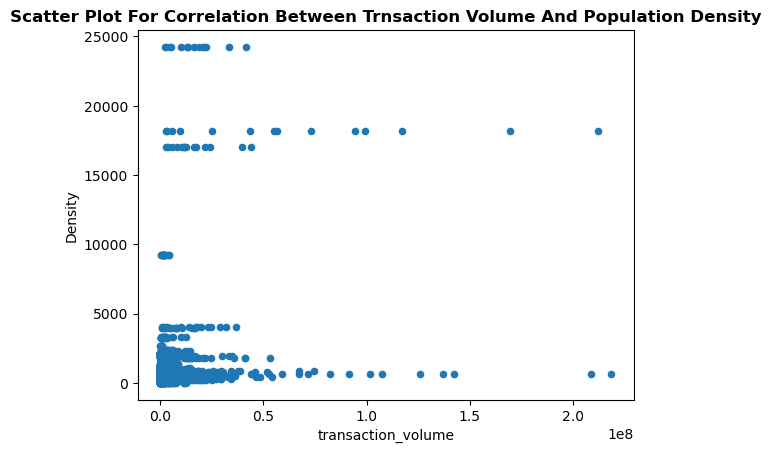

In [260]:
district_transaction_vol_pop_density.plot(kind = "scatter",x = "transaction_volume",y = "Density")
plt.title("Scatter Plot For Correlation Between Trnsaction Volume And Population Density",fontweight = "bold")

In [261]:
print("A positive weak relation can be observed this means that areas with high population density are likely to see a slight higher transaction volume than the areas with low population density")

A positive weak relation can be observed this means that areas with high population density are likely to see a slight higher transaction volume than the areas with low population density


# TASK 4 PART 3

In [262]:
avg_trans_amt = all_sheets["State_Txn and Users"].copy()


In [263]:
avg_trans_amt["trans_amt_per_user"] = avg_trans_amt["Amount (INR)"]/avg_trans_amt["Registered Users"]

In [264]:
avg_trans_amt = avg_trans_amt.groupby("State")["trans_amt_per_user"].mean()

In [265]:
avg_trans_amt = avg_trans_amt.sort_values(ascending = False)

In [266]:
avg_trans_amt

State
Telangana                              23774.0411271472
Karnataka                              17318.8639691594
Andhra Pradesh                         16703.9552508764
Delhi                                  14791.8851617717
Rajasthan                              13708.1174741659
Chandigarh                             12860.4716850233
Odisha                                 12378.1167838367
Madhya Pradesh                         12151.2511941170
Manipur                                11644.0514719223
Bihar                                  11287.1378327197
Maharashtra                            10946.4309630460
Haryana                                10362.1297407093
Jammu & Kashmir                        10217.2581229691
Arunachal Pradesh                       9868.0938520992
Tamil Nadu                              9851.6583868523
Sikkim                                  9587.1604029620
Nagaland                                9560.2903300973
Mizoram                                 94

In [267]:
top_states = " , ".join(list(avg_trans_amt.index[:5]))

In [268]:
bottom_states = " , ".join(list(avg_trans_amt.index[-5:]))

In [269]:
print(f"Top 5 States With Highest Transaction Amount Per User Are - {top_states}")

Top 5 States With Highest Transaction Amount Per User Are - Telangana , Karnataka , Andhra Pradesh , Delhi , Rajasthan


In [270]:
print(f"Top 5 States With Lowest Transaction Amount Per User Are - {bottom_states}")

Top 5 States With Lowest Transaction Amount Per User Are - Himachal Pradesh , Dadra & Nagar Haveli and Daman & Diu , Kerala , Lakshadweep , Tripura


# TASK 4 PART 4

In [271]:
all_sheets["State_DeviceData"].head()

,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.2470326409
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.2143916914
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.1456973294
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.0743323442
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.0492581602


In [272]:
state_device_data_copy = all_sheets["State_DeviceData"].copy()

In [273]:
state_device_data_copy.head()

,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.2470326409
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.2143916914
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.1456973294
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.0743323442
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.0492581602


In [274]:
all_sheets["State_Txn and Users"].head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [275]:
state_user_data_copy = all_sheets["State_Txn and Users"].copy()

In [276]:
state_user_data_copy.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [277]:
state_user_data_copy = state_user_data_copy[["State","Year","Quarter","Registered Users"]]

In [278]:
state_user_data_copy.head()

,State,Year,Quarter,Registered Users
0,Andaman & Nicobar Islands,2018,1,6740
1,Andaman & Nicobar Islands,2018,2,9405
2,Andaman & Nicobar Islands,2018,3,12149
3,Andaman & Nicobar Islands,2018,4,15222
4,Andaman & Nicobar Islands,2019,1,18596


In [279]:
brand_ratio = pd.merge(state_device_data_copy,state_user_data_copy,on = ["State","Year","Quarter"], suffixes = ["_device","_total"])

In [280]:
brand_ratio.head()

,State,Year,Quarter,Brand,Registered Users_device,Percentage,Registered Users_total
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.2470326409,6740
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.2143916914,6740
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.1456973294,6740
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.0743323442,6740
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.0492581602,6740


In [281]:
brand_ratio["brand_ratio_to_users"] = brand_ratio["Registered Users_device"]/brand_ratio["Registered Users_total"]

In [282]:
brand_ratio.head()

,State,Year,Quarter,Brand,Registered Users_device,Percentage,Registered Users_total,brand_ratio_to_users
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.2470326409,6740,0.2470326409
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.2143916914,6740,0.2143916914
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.1456973294,6740,0.1456973294
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.0743323442,6740,0.0743323442
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.0492581602,6740,0.0492581602


In [283]:
brand_ratio = brand_ratio.groupby(["State","Brand"])["brand_ratio_to_users"].mean().reset_index()

In [284]:
brand_ratio.head()

,State,Brand,brand_ratio_to_users
0,Andaman & Nicobar Islands,Apple,0.0257189547
1,Andaman & Nicobar Islands,Huawei,0.0278715522
2,Andaman & Nicobar Islands,Lenovo,0.0209838020
3,Andaman & Nicobar Islands,Motorola,0.0264084723
4,Andaman & Nicobar Islands,OnePlus,0.0416363834


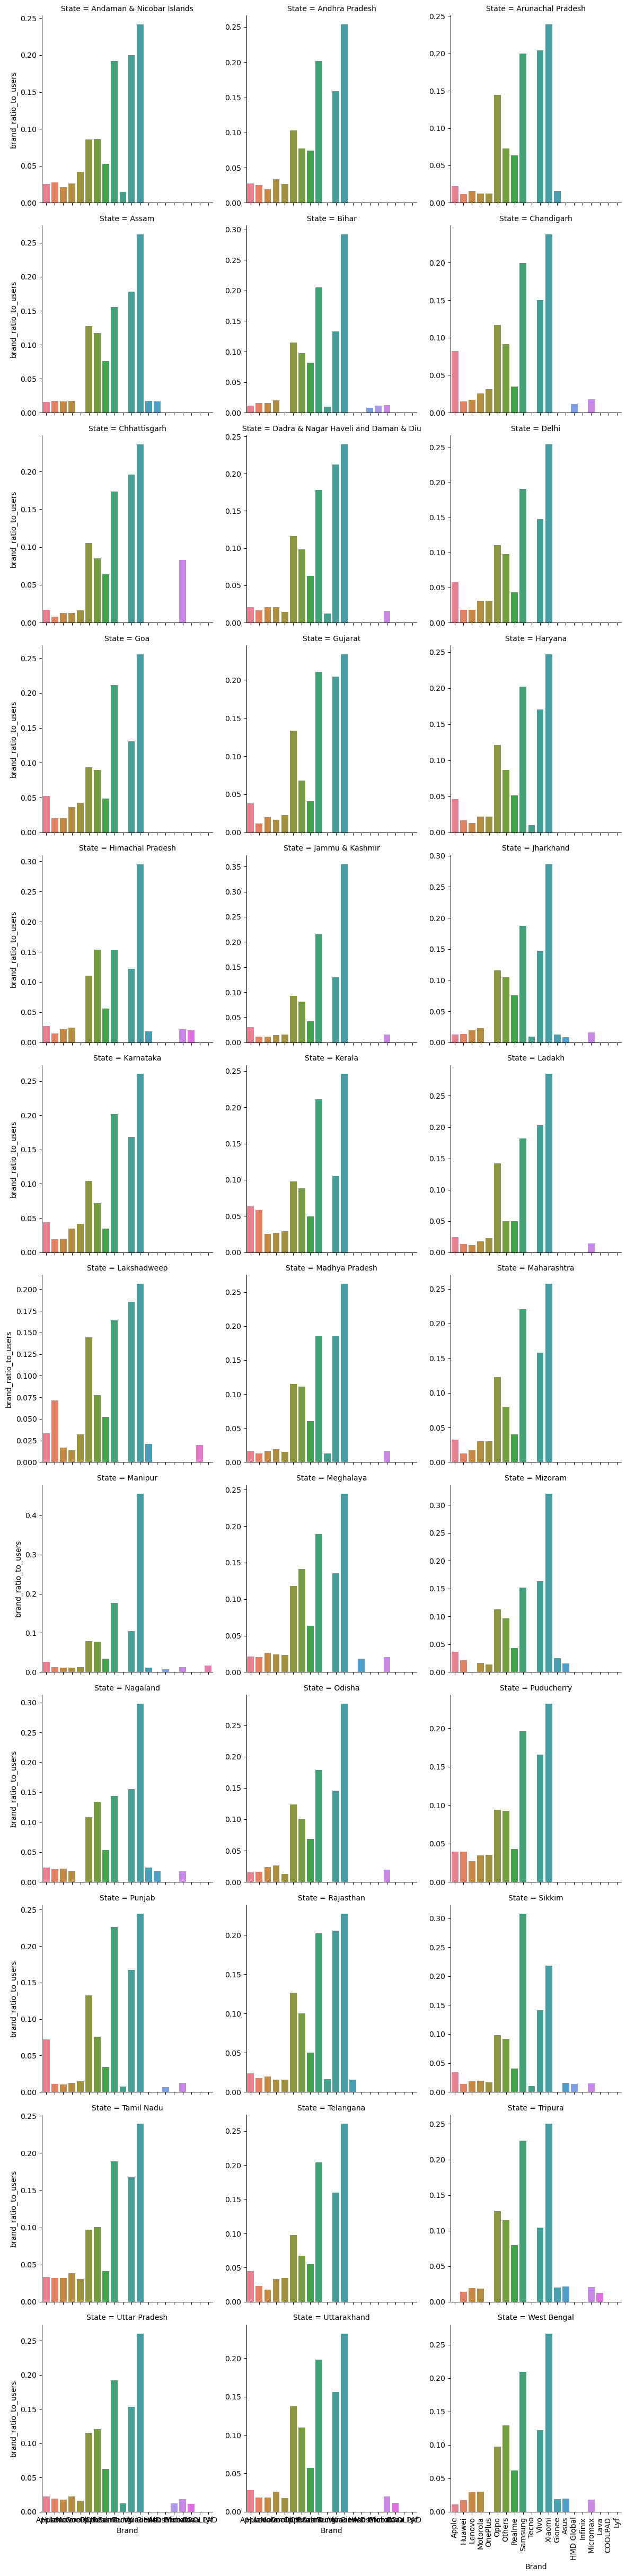

In [285]:
g = sns.catplot(data = brand_ratio, x = "Brand", y = "brand_ratio_to_users",col = "State",col_wrap = 3, height = 4, kind = "bar", hue = "Brand",sharey = False)
plt.xticks(rotation = "vertical")
plt.show()

# TASK 5 PART 1

In [286]:
state_txn_copy = all_sheets["State_Txn and Users"].copy()

In [287]:
select_state = input("Enter a state to get its data visual: ")

Enter a state to get its data visual:  Goa


In [288]:
state_txn_copy = state_txn_copy[state_txn_copy["State"] == select_state]

In [289]:
state_txn_copy["year_quarter"] = state_txn_copy["Year"].astype("str") + " " + state_txn_copy["Quarter"].astype("str") + "Q"

In [290]:
state_txn_copy = state_txn_copy.sort_values(by = ["Year","Quarter"])

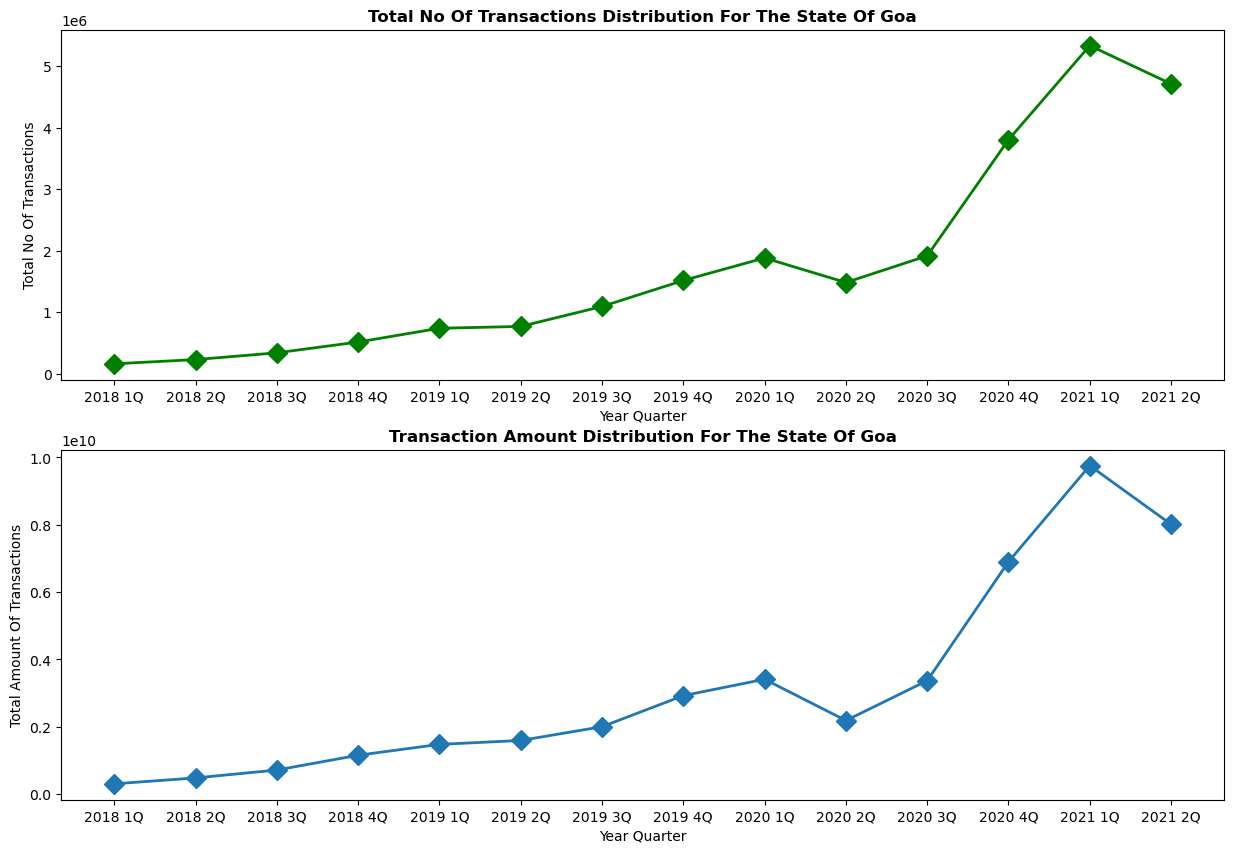

In [291]:
fig,ax = plt.subplots(nrows = 2, ncols = 1,figsize = (15,10))
ax[0].plot(state_txn_copy["year_quarter"],state_txn_copy["Transactions"],linewidth = 2, marker = "D", color = "green",markersize = 10)
ax[1].plot(state_txn_copy["year_quarter"],state_txn_copy["Amount (INR)"],linewidth = 2, marker = "D",markersize = 10)
ax[0].set_title(f"Total No Of Transactions Distribution For The State Of {select_state}",fontweight = "bold")
ax[1].set_title(f"Transaction Amount Distribution For The State Of {select_state}",fontweight = "bold")
ax[0].set_ylabel("Total No Of Transactions")
ax[1].set_ylabel("Total Amount Of Transactions")
ax[0].set_xlabel("Year Quarter")
ax[1].set_xlabel("Year Quarter")





plt.show()

# TASK 5 PART 2

In [292]:
 all_sheets["State_TxnSplit"].head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1845307.4673655001,439.3589208013
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,12138655.2997498997,6487.7901121058
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,452507.1686466130,1518.4804317000
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,10601.4199334649,321.2551494989
4,Andaman & Nicobar Islands,2018,1,Others,256,184689.8662902220,721.4447901962


In [293]:
all_sheets["State_TxnSplit"][(all_sheets["State_TxnSplit"].State == "West Bengal") & (all_sheets["State_TxnSplit"].Quarter == 2)]

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2449,West Bengal,2018,2,Peer-to-peer payments,8284944,15889890046.8628005981,1917.9236512477
2450,West Bengal,2018,2,Recharge & bill payments,7360522,1563841173.8396599293,212.4633516264
2451,West Bengal,2018,2,Financial Services,1121570,160809685.9388630092,143.3790899711
2452,West Bengal,2018,2,Merchant payments,937608,715914360.8192369938,763.5540234504
2453,West Bengal,2018,2,Others,377802,298728202.7433249950,790.7004270579
2469,West Bengal,2019,2,Peer-to-peer payments,20285958,48394974398.3783035278,2385.6390907631
2470,West Bengal,2019,2,Merchant payments,13646142,4657258459.1455402374,341.2875565230
2471,West Bengal,2019,2,Recharge & bill payments,12129638,3676123279.3800902367,303.0694963345
2472,West Bengal,2019,2,Financial Services,421037,45646046.9884630963,108.4133864446
2473,West Bengal,2019,2,Others,540760,331688935.2263129950,613.3754997158


In [294]:
state_txn_split = all_sheets["State_TxnSplit"].copy()

In [295]:
state_txn_split.tail()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,230812278789.2990112305,3569.5720255042
2510,West Bengal,2021,2,Merchant payments,41696787,34787867208.3192977905,834.3057034183
2511,West Bengal,2021,2,Recharge & bill payments,34799709,13331453857.6091995239,383.0909579620
2512,West Bengal,2021,2,Financial Services,190537,186466487.6307629943,978.6366303173
2513,West Bengal,2021,2,Others,549353,316744715.7049840093,576.5777481965


In [296]:
select_state_first = input("Enter State: ")
select_quart_first = int(input())

Enter State:  Goa
 1


In [297]:
state_txn_split =  state_txn_split[(state_txn_split.State == select_state_first) & (state_txn_split.Quarter == select_quart_first)]

In [298]:
state_txn_split.head(5)

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
630,Goa,2018,1,Recharge & bill payments,85991,18273814.1627086997,212.5084504507
631,Goa,2018,1,Peer-to-peer payments,59651,268175048.0699290037,4495.7343224745
632,Goa,2018,1,Merchant payments,7880,11036031.7356579006,1400.5116415810
633,Goa,2018,1,Financial Services,1191,520105.6424004220,436.6965931154
634,Goa,2018,1,Others,6184,5851742.7323869700,946.2714638401


In [299]:
state_txn_split = state_txn_split.groupby("Transaction Type")["Transactions"].sum().reset_index()

In [300]:
state_txn_split.head()

,Transaction Type,Transactions
0,Financial Services,13104
1,Merchant payments,2651026
2,Others,37183
3,Peer-to-peer payments,3491153
4,Recharge & bill payments,1920029


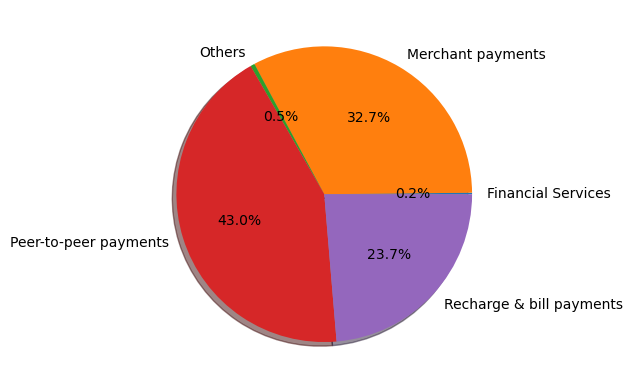

In [301]:
plt.pie(state_txn_split.Transactions,labels = state_txn_split["Transaction Type"],shadow = True,autopct = "%0.1f%%")
plt.show()

# TASK 5 PART 3

In [302]:
#TASK 5 PART 3
all_sheets["District Demographics"].head()


,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0000000000,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0000000000,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0000000000,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0000000000,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0000000000,188,AP13,YSR


In [303]:
district_demo_cpy = all_sheets["District Demographics"].copy()

In [304]:
select_state2 = input("Enter a state: ")

Enter a state:  Goa


In [305]:
district_demo_cpy = district_demo_cpy[district_demo_cpy.State == select_state2]

In [306]:
district_demo_cpy = district_demo_cpy[["District","Density"]].reset_index(drop = True)

In [307]:
district_demo_cpy.head()

,District,Density
0,North Goa,471
1,South Goa,326


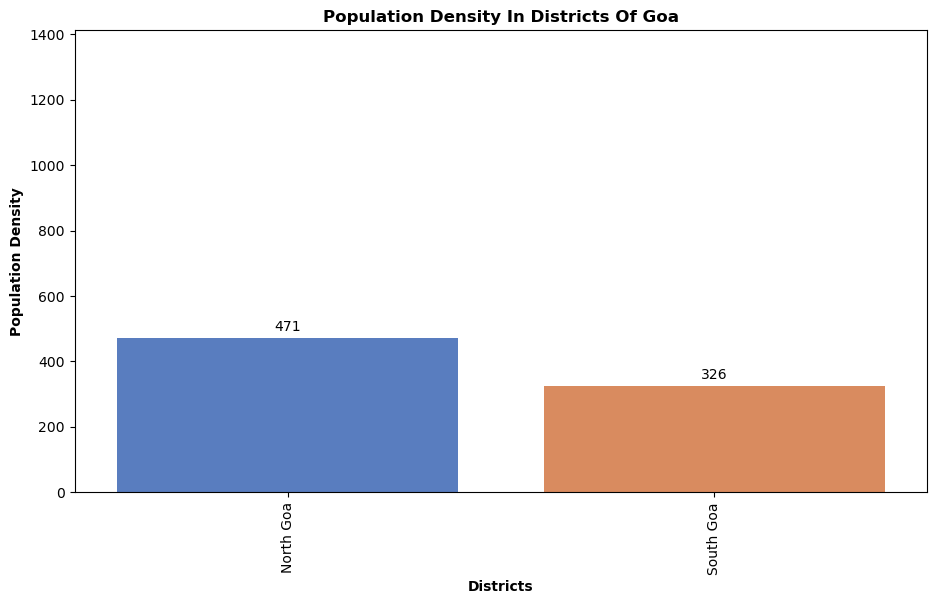

In [308]:
plt.figure(figsize = (11,6))


bars = sns.barplot(x = district_demo_cpy["District"],y = district_demo_cpy["Density"],hue = district_demo_cpy["District"], legend = False,palette = "muted")

for container in bars.containers:
    bars.bar_label(container,padding = 3,fmt = "%g")
plt.title(f"Population Density In Districts Of {select_state2}",fontweight = "bold")
plt.xlabel("Districts",fontweight = "bold")
plt.ylabel("Population Density",fontweight = "bold")
plt.xticks(rotation = "vertical")


plt.ylim(top = max(district_demo_cpy["Density"])*3)
plt.show()

# TASK 6 PART 1


In [309]:
#TASK 6 PART 1
all_sheets["State_Txn and Users"].head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


Taking mean in all calculations as complete data for 2021 not available

In [310]:
yearly_transactions = all_sheets["State_Txn and Users"].groupby("Year")["Transactions"].mean().reset_index().copy()

In [311]:
yearly_transactions = yearly_transactions.sort_values(by = "Year")

In [312]:
yearly_transactions

,Year,Transactions
0,2018,7501405.6250000000
1,2019,28332133.4375000000
2,2020,55374824.5902777761
3,2021,102763276.7777777761


In [313]:
yearly_transactions["Year"] = yearly_transactions["Year"].astype("int")

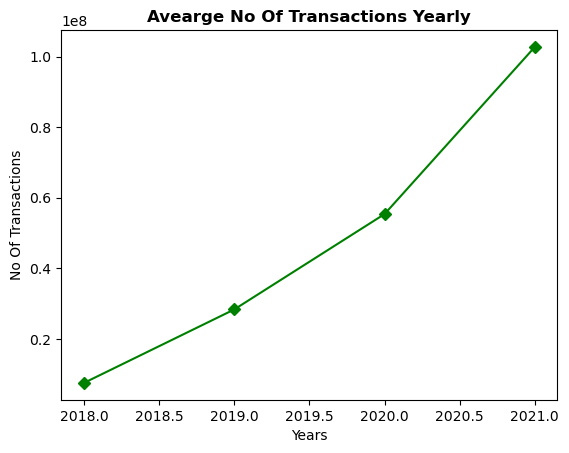

In [314]:
plt.plot(yearly_transactions["Year"],yearly_transactions["Transactions"],marker = "D",color = "green")
plt.title("Avearge No Of Transactions Yearly",fontweight = "bold")
plt.xlabel("Years")
plt.ylabel("No Of Transactions")
plt.grid(False)
plt.show()

In [315]:
print("In Last Three Years The Volume Of Transactions Have Increased More Than Five Times")

In Last Three Years The Volume Of Transactions Have Increased More Than Five Times


In [316]:
avg_registered_users_yearly = all_sheets["State_Txn and Users"].groupby("Year")["Registered Users"].mean().reset_index().copy()

In [317]:
avg_registered_users_yearly = avg_registered_users_yearly.sort_values(by = "Year")

In [318]:
avg_registered_users_yearly

,Year,Registered Users
0,2018,2033318.5555555555
1,2019,4186191.5138888890
2,2020,6402842.9513888890
3,2021,8197800.1666666670


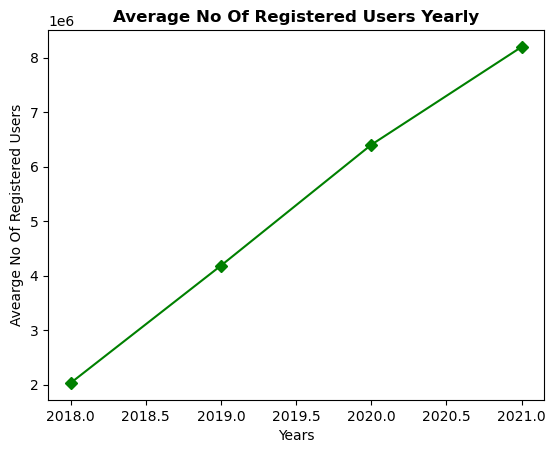

In [319]:
plt.plot(avg_registered_users_yearly["Year"],avg_registered_users_yearly["Registered Users"],marker = "D",color = "green")
plt.title("Average No Of Registered Users Yearly",fontweight = "bold")
plt.xlabel("Years")
plt.ylabel("Avearge No Of Registered Users")
plt.grid(False)
plt.show()

In [320]:
print("The Average No Of Registered Users On Phone Has Quadrupled")

The Average No Of Registered Users On Phone Has Quadrupled


In [321]:
avg_transaction_value_yearly = all_sheets["State_Txn and Users"].groupby("Year")["ATV (INR)"].mean().reset_index().copy()

In [322]:
avg_transaction_value_yearly = avg_transaction_value_yearly.sort_values(by = "Year")

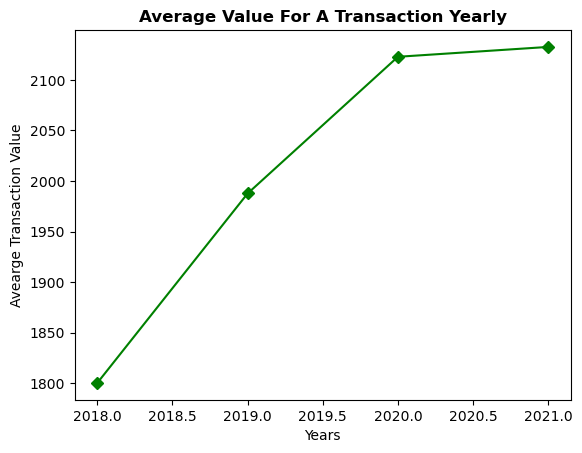

In [323]:
plt.plot(avg_transaction_value_yearly["Year"],avg_transaction_value_yearly["ATV (INR)"],marker = "D",color = "green")
plt.title("Average Value For A Transaction Yearly",fontweight = "bold")
plt.xlabel("Years")
plt.ylabel("Avearge Transaction Value")
plt.grid(False)
plt.show()

In [324]:
print("The Average Amount For A Transaction Has Increased By Around 20% In Last Three Years")

The Average Amount For A Transaction Has Increased By Around 20% In Last Three Years


In [325]:
print("The Above Three Visuals Could Be Interpreted As A Sign Of Increasing Adoption Of Online Payments At The National Level")

The Above Three Visuals Could Be Interpreted As A Sign Of Increasing Adoption Of Online Payments At The National Level


# TASK 6 PART 2 - Same As 4.2

# TASK 6 PART 3

In [326]:
# To rank devices in each state basd on ratio of device users to registered users 
brand_ratio.head()

,State,Brand,brand_ratio_to_users
0,Andaman & Nicobar Islands,Apple,0.0257189547
1,Andaman & Nicobar Islands,Huawei,0.0278715522
2,Andaman & Nicobar Islands,Lenovo,0.0209838020
3,Andaman & Nicobar Islands,Motorola,0.0264084723
4,Andaman & Nicobar Islands,OnePlus,0.0416363834


In [327]:
brand_ratio["brand rank in state"] = brand_ratio.groupby("State")["brand_ratio_to_users"].rank(ascending = False, method = "min")

In [328]:
brand_ratio = brand_ratio.sort_values(["State","brand rank in state"])


In [329]:
brand_ratio["brand rank in state"] = brand_ratio["brand rank in state"].astype("int")

In [330]:
print("Top 3 brands by brand user to registered users in each state are-")

Top 3 brands by brand user to registered users in each state are-


In [331]:
brand_ratio[brand_ratio["brand rank in state"].isin([1,2,3])]

,State,Brand,brand_ratio_to_users,brand rank in state
11,Andaman & Nicobar Islands,Xiaomi,0.2414754798,1
10,Andaman & Nicobar Islands,Vivo,0.1998578616,2
8,Andaman & Nicobar Islands,Samsung,0.1920538045,3
22,Andhra Pradesh,Xiaomi,0.2536600628,1
20,Andhra Pradesh,Samsung,0.2017714689,2
...,...,...,...,...
432,Uttarakhand,Samsung,0.1980777753,2
433,Uttarakhand,Vivo,0.1558205422,3
447,West Bengal,Xiaomi,0.2669949299,1
445,West Bengal,Samsung,0.2095911109,2


In [332]:
# To find best performing states based on Ttansaction volume and total amount
state_metrics_normal = all_sheets["State_Txn and Users"].copy()

In [333]:
state_metrics_normal.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,14631761.2219856996,2197.6210907158,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,28338535.5079534650,2498.9890218654,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,55557471.1343110576,3415.7682836957,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,90548336.0744550675,3811.2777201134,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,102299740.6734898388,3355.6301473952,18596,0


In [334]:
state_metrics_normal = state_metrics_normal.groupby("State").agg(tot_volume = ("Transactions","sum"), tot_amount = ("Amount (INR)","sum"))

In [335]:
state_metrics_normal = state_metrics_normal.reset_index()

In [336]:
state_metrics_normal.head()

,State,tot_volume,tot_amount
0,Andaman & Nicobar Islands,1223565,3641817860.7512121201
1,Andhra Pradesh,1781091169,3304012164384.1645507812
2,Arunachal Pradesh,8043799,22251830956.9066734314
3,Assam,123577981,281408712657.4358520508
4,Bihar,713643889,1639578926751.5102539062


In [337]:
def normalized(series):
    if series.min() == 0:
        return 0
    return (series - series.min())/(series.max() - series.min())

In [338]:
state_metrics_normal["normalized amt"] =  normalized(state_metrics_normal["tot_amount"])

In [339]:
state_metrics_normal["normalized vol"] =  normalized(state_metrics_normal["tot_volume"])

In [340]:
state_metrics_normal.head()

,State,tot_volume,tot_amount,normalized amt,normalized vol
0,Andaman & Nicobar Islands,1223565,3641817860.7512121201,0.0007541799,0.0003864359
1,Andhra Pradesh,1781091169,3304012164384.1645507812,0.7222958468,0.5974625080
2,Arunachal Pradesh,8043799,22251830956.9066734314,0.0048227838,0.0026743581
3,Assam,123577981,281408712657.4358520508,0.0614808157,0.0414315642
4,Bihar,713643889,1639578926751.5102539062,0.3584100380,0.2393756325


In [341]:
state_metrics_normal["composite vol amt"] = state_metrics_normal["normalized amt"] + state_metrics_normal["normalized vol"]

In [342]:
state_metrics_normal.head()

,State,tot_volume,tot_amount,normalized amt,normalized vol,composite vol amt
0,Andaman & Nicobar Islands,1223565,3641817860.7512121201,0.0007541799,0.0003864359,0.0011406158
1,Andhra Pradesh,1781091169,3304012164384.1645507812,0.7222958468,0.5974625080,1.3197583548
2,Arunachal Pradesh,8043799,22251830956.9066734314,0.0048227838,0.0026743581,0.0074971419
3,Assam,123577981,281408712657.4358520508,0.0614808157,0.0414315642,0.1029123799
4,Bihar,713643889,1639578926751.5102539062,0.3584100380,0.2393756325,0.5977856706


In [343]:
state_metrics_normal = state_metrics_normal.sort_values(by = "composite vol amt", ascending = False)

In [344]:
state_metrics_normal.head()

,State,tot_volume,tot_amount,normalized amt,normalized vol,composite vol amt
15,Karnataka,2981044533,4361395878908.1250000000,0.9534657847,1.0000000000,1.9534657847
20,Maharashtra,2833670154,4290995253332.0239257812,0.9380744863,0.9505616512,1.8886361375
31,Telangana,2347430243,4574245879737.8789062500,1.0000000000,0.7874471502,1.7874471502
1,Andhra Pradesh,1781091169,3304012164384.1645507812,0.7222958468,0.5974625080,1.3197583548
28,Rajasthan,1382918930,2625584351280.9785156250,0.5739749362,0.4638912716,1.0378662078


In [345]:
print("Top 5 states showing best performace in both volume and amount  are")

Top 5 states showing best performace in both volume and amount  are


In [346]:
state_metrics_normal["State"].head()

15         Karnataka
20       Maharashtra
31         Telangana
1     Andhra Pradesh
28         Rajasthan
Name: State, dtype: object

In [347]:
composite_best_states = " , ".join(list(state_metrics_normal["State"].values)[0:5])
composite_best_states

'Karnataka , Maharashtra , Telangana , Andhra Pradesh , Rajasthan'

In [348]:
print(f"The worst performing states by amount and volume metrics are")

The worst performing states by amount and volume metrics are


In [349]:
state_metrics_normal["State"].tail()

22                    Meghalaya
23                      Mizoram
17                       Ladakh
0     Andaman & Nicobar Islands
18                  Lakshadweep
Name: State, dtype: object

In [350]:
composite_worst_states = " , ".join(list(state_metrics_normal["State"].values)[-5:])
composite_worst_states

'Meghalaya , Mizoram , Ladakh , Andaman & Nicobar Islands , Lakshadweep'

In [351]:
# best and worst performing t types overall

In [352]:
all_sheets["State_TxnSplit"].head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1845307.4673655001,439.3589208013
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,12138655.2997498997,6487.7901121058
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,452507.1686466130,1518.4804317000
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,10601.4199334649,321.2551494989
4,Andaman & Nicobar Islands,2018,1,Others,256,184689.8662902220,721.4447901962


In [353]:
t_type_performance = all_sheets["State_TxnSplit"].groupby("Transaction Type")["Transactions"].sum()

In [354]:
t_type_performance = t_type_performance.head().reset_index()

In [355]:
t_type_performance.rename(columns = {"Transactions": "volume"},inplace = True)

In [356]:
t_type_performance

,Transaction Type,volume
0,Financial Services,47996333
1,Merchant payments,6959228853
2,Others,117964108
3,Peer-to-peer payments,9161937793
4,Recharge & bill payments,4245833207


In [357]:
t_type_performance["normalized volume"] = normalized(t_type_performance["volume"])

In [358]:
t_type_performance = t_type_performance.sort_values(by = "normalized volume", ascending = False)

In [359]:
t_type_performance

,Transaction Type,volume,normalized volume
3,Peer-to-peer payments,9161937793,1.0000000000
1,Merchant payments,6959228853,0.7583143419
4,Recharge & bill payments,4245833207,0.4605951105
2,Others,117964108,0.0076770051
0,Financial Services,47996333,0.0000000000


# Summary 

In [360]:
print("KEY FINDINGS AND INSIGHTS")
print()
print(f"In given dataset about transactions and demographics there are {tot_states} states and {tot_districts} districts. The state with maximum number of districts is {most_freq_state}")
print()
print("In states like - Telangana Karnataka Andra Pradesh and Rajasthan not only the volume of transaction is highest \nbut also the average amount of a transaction per user is also highest amongst all states.\nIn Rajasthan particularly it can also be observed the number of application open are highest \nthis shows a increasing popularity of application in Rajasthan.\n Although in states like Ladakh,Andaman and nicobar and mizoram the transaction volume is th lowest amongst all states but these states feature amongst highest average transaction value states.\n State of dadar and nagar haveli daman and diu show a bad performace in terms of both average transaction value as well as average transaction value per user.\nA similar case is observed in state of Lakshadweep where not only the volume of transactions is amongst lowest in all states\nbut also the average transaction value per user is in bottom 5.")
print()
print()

print("A surprising fact discovered during analysis of transaction types dataset\nrevealed that throughout the given period 'peer-to-peer' type transactions have dominated across most states followed by merchant transactions and recharge and bill payments.")
print()
print()
print(f"Overall based on a composite matrics analysis (total amount and volume of transactions) by normalisation method it was found that best 5 states on both metrics are {composite_best_states} and worst 5 stats are {composite_worst_states}")
print()
print()
print("As per the device related data for states its quite clear that most transactions are done using Xiomi brand devices")
print()
print(f"The pearson correlation value of {tran_vol_pop_density_correl} between population density and transaction volume could be concluded as a positive weak relationship which highlights the fact that areas with high population density would experince a slight increase in transaction volume.")

KEY FINDINGS AND INSIGHTS

In given dataset about transactions and demographics there are 36 states and 736 districts. The state with maximum number of districts is Uttar Pradesh

In states like - Telangana Karnataka Andra Pradesh and Rajasthan not only the volume of transaction is highest 
but also the average amount of a transaction per user is also highest amongst all states.
In Rajasthan particularly it can also be observed the number of application open are highest 
this shows a increasing popularity of application in Rajasthan.
 Although in states like Ladakh,Andaman and nicobar and mizoram the transaction volume is th lowest amongst all states but these states feature amongst highest average transaction value states.
 State of dadar and nagar haveli daman and diu show a bad performace in terms of both average transaction value as well as average transaction value per user.
A similar case is observed in state of Lakshadweep where not only the volume of transactions is amongst low

# RECOMMENDATIONS


In [362]:
print(f"Based on a composite metric in states with poor performance like - {composite_worst_states} \nmaketing campaigns must be launched to increase awarness and built trust in users the situation must be monitored further to see improvements.")
print()
print("In transaction types the 'recharge and bill payments' is a essential transaction type but stand at 3rd place by transaction volume (having a transaction volume of less than half for what it is for peer-to-peer transaction type) \nsimply offering new offer and promotions may result in a increased volume of such a transaction type")

Based on a composite metric in states with poor performance like - Meghalaya , Mizoram , Ladakh , Andaman & Nicobar Islands , Lakshadweep 
maketing campaigns must be launched to increase awarness and built trust in users the situation must be monitored further to see improvements.

In transaction types the 'recharge and bill payments' is a essential transaction type but stand at 3rd place by transaction volume (having a transaction volume of less than half for what it is for peer-to-peer transaction type) 
simply offering new offer and promotions may result in a increased volume of such a transaction type
